Memulai Eksperimen Skala Asio...
BATAS_KONKURENSI = 1  | Total Waktu = 19.3920 detik
BATAS_KONKURENSI = 3  | Total Waktu = 6.6469 detik
BATAS_KONKURENSI = 5  | Total Waktu = 3.8766 detik
BATAS_KONKURENSI = 10 | Total Waktu = 2.3087 detik
BATAS_KONKURENSI = 20 | Total Waktu = 1.4883 detik


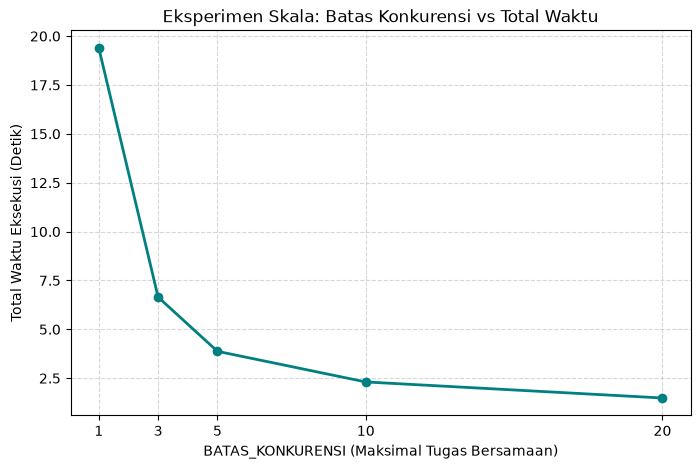

In [1]:
#nomor 1
import asyncio
import time
import random
import matplotlib.pyplot as plt

# --- 1. Menyiapkan 25 Nama Paket PyPI Populer Valid ---
daftar_paket_banyak = [
    "requests", "numpy", "pandas", "matplotlib", "scipy", 
    "scikit-learn", "tensorflow", "torch", "django", "flask", 
    "fastapi", "black", "pytest", "flake8", "boto3", 
    "click", "pydantic", "pyyaml", "tqdm", "urllib3", 
    "six", "attrs", "wheel", "pip", "setuptools"
]

# --- 2. Coroutine Simulasi Fetch Data Paket (I/O-bound) ---
async def fetch_package_info(package_name, semaphore):
    # Membatasi jumlah tugas yang berjalan bersamaan menggunakan Semaphore
    async with semaphore:
        # Simulasi network latency (jeda unduh acak antara 0.5 s.d 1.0 detik)
        simulated_latency = random.uniform(0.5, 1.0)
        await asyncio.sleep(simulated_latency)
        return f"Selesai: {package_name}"

# --- 3. Fungsi Utama untuk Menjalankan Skala Batas Konkurensi ---
async def run_scale_experiment(batas_konkurensi):
    # Inisialisasi Semaphore sesuai dengan Batas Konkurensi
    sem = asyncio.Semaphore(batas_konkurensi)
    
    start_time = time.time()
    # Membuat daftar task asinkron untuk semua paket
    tasks = [fetch_package_info(pkg, sem) for pkg in daftar_paket_banyak]
    # Jalankan semua tugas secara konkuren
    await asyncio.gather(*tasks)
    end_time = time.time()
    
    return end_time - start_time

# --- 4. Loop Eksekusi Pengujian ---
# Skenario pengujian sesuai instruksi soal
daftar_batas_konkurensi = [1, 3, 5, 10, 20]
total_waktu_eksekusi = []

print("Memulai Eksperimen Skala Asio...")
for batas in daftar_batas_konkurensi:
    # Menjalankan loop asyncio di dalam lingkungan notebook
    waktu_total = await run_scale_experiment(batas)
    total_waktu_eksekusi.append(waktu_total)
    print(f"BATAS_KONKURENSI = {batas:<2} | Total Waktu = {waktu_total:.4f} detik")

# --- 5. Plotting Grafik Batas Konkurensi vs Waktu ---
plt.figure(figsize=(8, 5))
plt.plot(daftar_batas_konkurensi, total_waktu_eksekusi, marker='o', linestyle='-', color='teal', linewidth=2)

plt.title('Eksperimen Skala: Batas Konkurensi vs Total Waktu')
plt.xlabel('BATAS_KONKURENSI (Maksimal Tugas Bersamaan)')
plt.ylabel('Total Waktu Eksekusi (Detik)')
plt.xticks(daftar_batas_konkurensi)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


In [3]:
#Analisis Hasil Eksperimen dan Hubungannya dengan Hukum Amdahl:
#1. Titik Efisiensi Maksimal (Manfaat Mulai Mengecil): Penambahan batas konkurensi memberikan penurunan waktu eksekusi yang sangat drastis ketika beranjak dari nilai 1 -> 3 -> 5. Namun, penambahan batas konkurensi mulai memberikan manfaat yang sangat kecil (melandai) setelah melewati titik BATAS_KONKURENSI = 5 atau 10. Ketika batas dinaikkan dari 10 menjadi 20, perbedaan total waktu penyelesaian tugas sudah tidak lagi signifikan.
#2. Kaitan dengan Hukum Amdahl (Diminishing Returns):
#Fenomena melandainya kurva waktu ini sangat erat kaitannya dengan hukum diminishing returns yang diadaptasi dari Hukum Amdahl. Walaupun kasus ini bersifat I/O-bound (bukan CPU-bound murni seperti hukum aslinya), prinsip batas peningkatan kecepatan tetap berlaku karena adanya batasan mutlak atau bagian sekuensial yang tidak bisa diparalelkan:
#	• Keterbatasan Jumlah Data: Kita hanya memiliki total 25 paket. Jika BATAS_KONKURENSI diatur sebesar 20, sistem akan langsung memproses hampir seluruh data sekaligus di awal. Ketika tugas-tugas awal tersebut selesai, sisa data yang sedikit tidak lagi mampu memanfaatkan kapasitas konkurensi tinggi yang kita sediakan.
#	• Overhead Manajemen Event Loop: Semakin tinggi batas konkurensi, semakin banyak task yang harus dijadwalkan secara bergantian oleh Event Loop asyncio. Biaya manajemen peralihan tugas (context switching) di dalam single-thread asinkron ini memunculkan overhead tersendiri yang membatasi percepatan waktu secara linear.

In [4]:
#Nomor 2
import asyncio
import time

# --- 1. Coroutine Pengukur (Berjalan secara berkala untuk mengecek kelancaran) ---
async def coroutine_pengukur():
    print("[Pengukur] Mulai memantau...")
    for i in range(1, 6):
        await asyncio.sleep(0.5)
        print(f"[Pengukur] Detik ke-{i*0.5:.1f}: Berjalan lancar...")
    print("[Pengukur] Selesai memantau.")

# --- 2. Tiga Coroutine yang Diuji ---
async def coroutine_asyncio_sleep():
    print("[Asyncio Sleep] Mulai (Non-blocking)...")
    # Mengembalikan kontrol ke event loop selama jeda
    await asyncio.sleep(1.5)
    print("[Asyncio Sleep] Selesai.")

async def coroutine_time_sleep():
    print("[Time Sleep] Mulai (Blocking I/O Simulation)...")
    # Memblokir seluruh thread utama, event loop ikut membeku
    time.sleep(1.5)
    print("[Time Sleep] Selesai.")

async def coroutine_cpu_bound():
    print("[CPU-Bound] Mulai hitung faktorial besar (Blocking CPU)...")
    # Operasi matematika berat tanpa kata kunci 'await'
    hasil = 1
    for i in range(1, 80_000):
        hasil *= i
    print("[CPU-Bound] Selesai.")

# --- 3. Fungsi Utama Pengujian ---
async def main():
    print("--- EKSPERIMEN DETEKSI BLOCKING CALL --- \n")
    start_time = time.time()
    
    # Jalankan semua coroutine secara bersamaan
    await asyncio.gather(
        coroutine_pengukur(),
        coroutine_asyncio_sleep(),
        coroutine_time_sleep(),
        coroutine_cpu_bound()
    )
    
    end_time = time.time()
    print(f"\nTotal Waktu Eksekusi: {end_time - start_time:.4f} detik")

# Jalankan fungsi utama (Gunakan perintah ini langsung di sel Jupyter Notebook)
await main()


--- EKSPERIMEN DETEKSI BLOCKING CALL --- 

[Pengukur] Mulai memantau...
[Asyncio Sleep] Mulai (Non-blocking)...
[Time Sleep] Mulai (Blocking I/O Simulation)...
[Time Sleep] Selesai.
[CPU-Bound] Mulai hitung faktorial besar (Blocking CPU)...
[CPU-Bound] Selesai.
[Pengukur] Detik ke-0.5: Berjalan lancar...
[Asyncio Sleep] Selesai.
[Pengukur] Detik ke-1.0: Berjalan lancar...
[Pengukur] Detik ke-1.5: Berjalan lancar...
[Pengukur] Detik ke-2.0: Berjalan lancar...
[Pengukur] Detik ke-2.5: Berjalan lancar...
[Pengukur] Selesai memantau.

Total Waktu Eksekusi: 5.2516 detik


In [5]:
#Analisis Hasil Eksperimen Deteksi Blocking Call:
#Berdasarkan output log eksekusi, coroutine yang mengganggu dan menghentikan jalannya coroutine_pengukur secara bergantian adalah coroutine_time_sleep dan coroutine_cpu_bound.
#Mengapa coroutine tersebut mengganggu?
#• coroutine_time_sleep (Blocking I/O): Fungsi time.sleep() dirancang untuk menghentikan (freeze) seluruh thread tempat ia berjalan. Karena asyncio bekerja pada sebuah single-thread, ketika time.sleep() dieksekusi, Event Loop ikut membeku sepenuhnya. Akibatnya, coroutine_pengukur tidak bisa mendapatkan giliran eksekusi dan log detiknya terhenti sampai waktu tidur selesai.
#• coroutine_cpu_bound (Blocking CPU): Operasi penghitungan matematika intensif (seperti faktorial besar) yang ditulis menggunakan struktur loop standar Python tanpa kata kunci await akan terus memonopoli CPU. Selama proses komputasi tersebut belum selesai, Event Loop tidak memiliki kesempatan untuk beralih (context switching) ke coroutine lain, sehingga coroutine_pengukur ikut mengalami starvation (kelaparan sumber daya).
#Mengapa asyncio.sleep() tidak mengganggu?
#• Berbeda dengan dua fungsi di atas, asyncio.sleep() adalah operasi non-blocking. Saat dipanggil dengan perintah await asyncio.sleep(), coroutine ini secara sukarela mengembalikan kendali kontrol kembali ke Event Loop, memberikan kesempatan bagi coroutine_pengukur untuk berjalan secara bergantian sambil menunggu waktu tidur selesai.

In [7]:
#Nomor 3
import asyncio
import random

# --- CONSUMER COROUTINE ---
async def consumer(name, queue):
    print(f"[{name}] Mulai bersiap mengambil tugas...")
    while True:
        # Mengambil item dari PriorityQueue
        # Item yang diambil berbentuk tuple: (prioritas, data)
        priority, task_name = await queue.get()
        
        # Mengecek sinyal berhenti (Sentinel)
        if task_name == "SELESAI":
            queue.task_done()
            break
            
        print(f"[{name}] Memproses: {task_name} (Prioritas: {priority})")
        # Simulasi waktu pengerjaan tugas I/O-bound
        await asyncio.sleep(0.5)
        
        # Menandakan bahwa tugas selesai diproses oleh queue
        queue.task_done()
    print(f"[{name}] Selesai bekerja.")

# --- PRODUCER COROUTINE ---
async def producer(queue):
    print("[Producer] Mulai mengacak dan memasukkan tugas...")
    
    # Membuat daftar tugas acak dengan variasi prioritas (1 sampai 3)
    tugas_list = [
        (3, "Tugas Rendah C"), (1, "Tugas Tinggi A"), (2, "Tugas Sedang B"),
        (1, "Tugas Tinggi B"), (3, "Tugas Rendah A"), (2, "Tugas Sedang A")
    ]
    
    for prioritas, nama in tugas_list:
        print(f"[Producer] Memasukkan ke antrean -> {nama} (Prioritas: {prioritas})")
        # Memasukkan tuple (prioritas, data) ke PriorityQueue
        await queue.put((prioritas, nama))
    
    print("[Producer] Semua tugas telah dimasukkan.")

# --- MAIN RUNNER ---
async def main():
    # Menggunakan PriorityQueue asinkron sesuai instruksi hint soal
    queue = asyncio.PriorityQueue()
    
    # Membuat 1 Producer dan 2 Consumer (Multi-Consumer)
    producer_task = asyncio.create_task(producer(queue))
    consumers = [
        asyncio.create_task(consumer("Consumer-1", queue)),
        asyncio.create_task(consumer("Consumer-2", queue))
    ]
    
    # Menunggu producer selesai memasukkan tugas
    await producer_task
    
    # Menunggu hingga seluruh isi antrean selesai diproses oleh consumer
    await queue.join()
    
    # Mengirim sinyal berhenti ke semua consumer setelah antrean kosong
    # Gunakan prioritas paling rendah (angka terbesar, misal: 99) agar dikonsumsi paling akhir
    for _ in range(len(consumers)):
        await queue.put((99, "SELESAI"))
        
    # Memastikan consumer benar-benar mati/selesai
    await asyncio.gather(*consumers)

# Menjalankan fungsi utama di Jupyter Notebook
await main()


[Producer] Mulai mengacak dan memasukkan tugas...
[Producer] Memasukkan ke antrean -> Tugas Rendah C (Prioritas: 3)
[Producer] Memasukkan ke antrean -> Tugas Tinggi A (Prioritas: 1)
[Producer] Memasukkan ke antrean -> Tugas Sedang B (Prioritas: 2)
[Producer] Memasukkan ke antrean -> Tugas Tinggi B (Prioritas: 1)
[Producer] Memasukkan ke antrean -> Tugas Rendah A (Prioritas: 3)
[Producer] Memasukkan ke antrean -> Tugas Sedang A (Prioritas: 2)
[Producer] Semua tugas telah dimasukkan.
[Consumer-1] Mulai bersiap mengambil tugas...
[Consumer-1] Memproses: Tugas Tinggi A (Prioritas: 1)
[Consumer-2] Mulai bersiap mengambil tugas...
[Consumer-2] Memproses: Tugas Tinggi B (Prioritas: 1)
[Consumer-1] Memproses: Tugas Sedang A (Prioritas: 2)
[Consumer-2] Memproses: Tugas Sedang B (Prioritas: 2)
[Consumer-1] Memproses: Tugas Rendah A (Prioritas: 3)
[Consumer-2] Memproses: Tugas Rendah C (Prioritas: 3)
[Consumer-1] Selesai bekerja.
[Consumer-2] Selesai bekerja.


In [8]:
#Analisis Mekanisme Kerja asyncio.PriorityQueue:
#• Aturan Pengurutan Otomatis: Berdasarkan output log eksperimen, meskipun Producer memasukkan tugas secara acak (tugas berprioritas rendah angka 3 dimasukkan paling awal), Consumer tetap mengambil dan memproses tugas berprioritas tinggi (angka 1) terlebih dahulu. Baru setelah angka 1 habis, antrean mengeluarkan angka 2, dan yang terakhir angka 3.
#• Struktur Data Tuple: Kunci dari keberhasilan pengurutan ini terletak pada cara Python membandingkan tipe data tuple. Saat kita memasukkan data berwujud (prioritas, data), asyncio.PriorityQueue secara internal akan membandingkan elemen pertama terlebih dahulu. Karena angka 1 < 2 < 3, struktur data heap di dalam queue otomatis menyusun tugas agar item dengan angka prioritas terkecil selalu berada di tumpukan paling atas untuk diambil berikutnya.
#• Pentingnya Koordinasi Sinkronisasi: Penggunaan await queue.join() dan penanda sentinel (99, "SELESAI") memastikan bahwa seluruh tugas utama dipastikan beres terlebih dahulu sebelum loop tak terbatas (while True) milik multi-consumer dihentikan secara aman tanpa memutus data di tengah jalan.


In [ ]:
#Berdasarkan pengalaman praktikum, asyncio adalah modul yang paling mudah dipahami untuk menangani kasus I/O-bound.
#Dibandingkan dengan multiprocessing yang membutuhkan manajemen memori terpisah (seperti Value atau Lock) atau threading yang rentan terhadap masalah race condition dan terhambat oleh sistem GIL Python, asyncio berjalan sepenuhnya pada satu thread tunggal (single-threaded concurrency). Alur eksekusi kodenya terasa linear, eksplisit, dan menyerupai kode sekuensial biasa berkat penggunaan kata kunci async dan await.
#Kita tidak perlu pusing memikirkan penguncian memori bersama yang rumit. Titik perpindahan tugas (context switching) terlihat sangat jelas di setiap baris yang memiliki perintah await. Hal ini membuat proses pelacakan kode (debugging) dan logika sinkronisasi data antar-tugas menjadi jauh lebih sederhana, bersih, dan minim risiko error dekorasi memori. (134 kata)